In [1]:
import xarray as xr
ds = xr.open_dataset("/mnt/CORDEX_CMIP6_tmp/sim_data/CORDEX-CMIP6/DD/EUR-12/GERICS/ERA5/evaluation/r1i1p1f1/REMO2020-2-2/v1-r1/mon/tas/v20241120/tas_EUR-12_ERA5_evaluation_r1i1p1f1_GERICS_REMO2020-2-2_v1-r1_mon_197901-198812.nc")
ds

<xarray.Dataset> Size: 98MB
Dimensions:                     (time: 120, bnds: 2, rlat: 412, rlon: 424,
                                 vertices: 4)
Coordinates:
  * time                        (time) datetime64[ns] 960B 1979-01-16T12:00:0...
  * rlat                        (rlat) float64 3kB -23.38 -23.27 ... 21.73 21.84
  * rlon                        (rlon) float64 3kB -28.38 -28.27 ... 18.05 18.16
    lat                         (rlat, rlon) float64 1MB ...
    lon                         (rlat, rlon) float64 1MB ...
    height                      float64 8B ...
Dimensions without coordinates: bnds, vertices
Data variables:
    time_bnds                   (time, bnds) datetime64[ns] 2kB ...
    rotated_latitude_longitude  int32 4B ...
    vertices_lat                (rlat, rlon, vertices) float64 6MB ...
    vertices_lon                (rlat, rlon, vertices) float64 6MB ...
    tas                         (time, rlat, rlon) float32 84MB ...
Attributes: (12/38)
    CORDEX_domain:           EUR-11
    Conventions:             CF-1.11
    activity_id:             DD
    comment:                 original REMO run id: 065020
    contact:                 gerics-cordex@hereon.de
    creation_date:           2025-09-25T16:13:15Z
    ...                      ...
    tracking_id:             hdl:21.14103/6482aca9-6856-40e8-a255-e4be9d1d9646
    variable_id:             tas
    version:                 v20241120
    version_realization:     v1-r1
    license:                 https://cordex.org/data-access/cordex-cmip6-data...
    cmor_version:            3.12.0

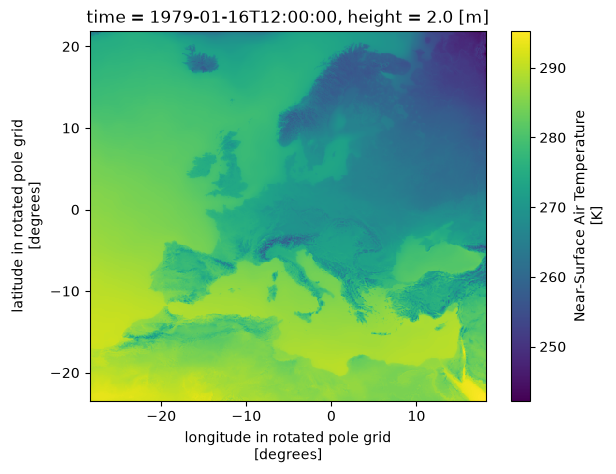

In [2]:
ds.tas.isel(time=0).plot()

In [3]:
ds.tas

<xarray.DataArray 'tas' (time: 120, rlat: 412, rlon: 424)> Size: 84MB
[20962560 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 960B 1979-01-16T12:00:00 ... 1988-12-16T12...
  * rlat     (rlat) float64 3kB -23.38 -23.27 -23.16 ... 21.61 21.73 21.84
  * rlon     (rlon) float64 3kB -28.38 -28.27 -28.16 ... 17.93 18.05 18.16
    lat      (rlat, rlon) float64 1MB ...
    lon      (rlat, rlon) float64 1MB ...
    height   float64 8B ...
Attributes:
    standard_name:  air_temperature
    long_name:      Near-Surface Air Temperature
    units:          K
    cell_methods:   area: time: mean
    cell_measures:  area: areacella
    history:        2025-09-25T16:13:12Z altered by CMOR: Treated scalar dime...
    grid_mapping:   rotated_latitude_longitude

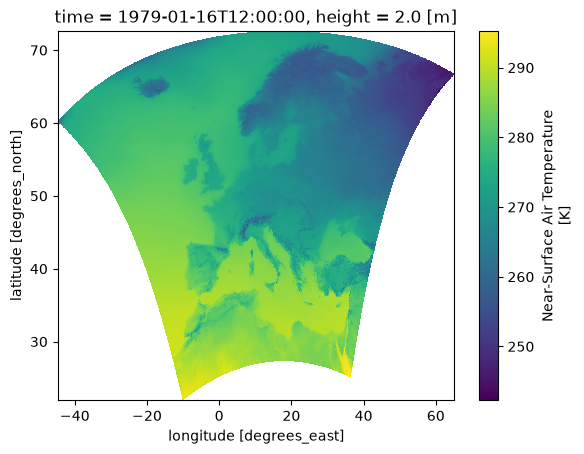

In [4]:
ds.tas.isel(time=0).plot(x="lon", y="lat")

/home/skotlarski/.conda/envs/evaltools-py312/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/home/skotlarski/.conda/envs/evaltools-py312/lib/python3.12/site-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_cultural/ne_110m_admin_0_boundary_lines_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


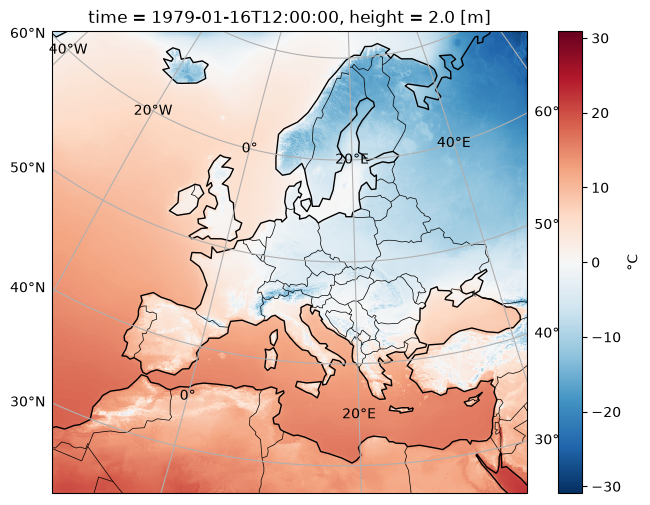

In [5]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

gm = ds.rotated_latitude_longitude.attrs   # grid mapping variable; name may differ
rp = ccrs.RotatedPole(
    pole_longitude=gm["grid_north_pole_longitude"],
    pole_latitude=gm["grid_north_pole_latitude"],
)

fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=rp)
(ds.tas.isel(time=0) - 273.15).plot(ax=ax, transform=rp, cbar_kwargs={"label": "°C"})
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.gridlines(draw_labels=True)
